# 실습 03 · YOLO 라벨 읽기

> **Day15 | 객체탐지·YOLO·추적 · 01_기본필수**
> 원본 스크립트: `03_labels.py` · 교안 PPT 39쪽 · 직접 구현: B04
> 결과: 이 노트북을 실제 실행한 출력

## 학습 목표

- YOLO TXT 한 줄 `class cx cy w h`의 의미를 설명한다.
- 정규화 좌표를 픽셀 박스로 되돌려 그림 위에 그려 확인한다.
- 너비·높이를 바꿔 정규화하면 생기는 오류를 직접 본다.

## 핵심 개념

| 개념 | 설명 |
|---|---|
| cx, cy | 박스 중심 / 이미지 W, H (0~1) |
| w, h | 박스 폭·높이 / 이미지 W, H (0~1) |
| 빈 TXT | 객체 0개인 정상 negative (파일 누락과 다름) |
| 160×128 | W=160, H=128 → 정사각형이 아님 |

## 0. 준비

- 이 노트북은 `01_기본필수` 폴더(같은 폴더에 `data/`가 있는 위치)에서 연다.
- 입력은 `data/`의 원본을 읽기만 하고, 노트북이 만드는 결과 파일은 `outputs_notebook/`에 저장한다.
- CPU에서 실행한다. GPU·CUDA 코드는 없다.

In [1]:
# ============================================================
# 0. 라이브러리·경로 설정
# ============================================================
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# BASE : 노트북 폴더(01_기본필수) / DATA : 원본 입력 / OUT : 노트북 결과 폴더
BASE = Path.cwd()
DATA = BASE / "data"
OUT = BASE / "outputs_notebook"
OUT.mkdir(exist_ok=True)

def show(images, titles, size=3.2):
    """BGR 배열 여러 장을 한 줄로 표시한다.

    - images: BGR 배열 목록 (OpenCV로 읽은 그대로)
    - titles: 각 그림 제목 목록
    """
    fig, axes = plt.subplots(1, len(images), figsize=(size * len(images), size * 0.9))
    axes = np.atleast_1d(axes)
    for ax, img, title in zip(axes, images, titles):
        # cv2.cvtColor(BGR2RGB) : matplotlib은 RGB 순서로 그리므로 채널 순서를 바꿈
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 1. 라벨 파일 읽기 (TODO B04)

`read_text(encoding="utf-8")`로 문자열을 읽고 `splitlines()`로 줄 목록을 만든다.

In [2]:
# ============================================================
# 1. 라벨 파일 읽기 (TODO B04)
# ============================================================
names = ["square", "circle", "triangle"]
records = []
for image_path in sorted((DATA / "images/train").glob("*.png"))[:6]:
    image = cv2.imread(str(image_path))
    label_path = DATA / "labels/train" / (image_path.stem + ".txt")
    # B04 : 문자열 읽기 -> 줄 목록
    lines = (
        label_path
        .read_text(encoding="utf-8")
        .splitlines()
    )
    print(image_path.name, "shape:", image.shape, "boxes:", len(lines))
    for line in lines:
        cls, cx, cy, width, height = map(float, line.split())
        print(" ", names[int(cls)], "normalized:", cx, cy, width, height)
        records.append(dict(image=image_path.stem, cls=int(cls), cx=cx, cy=cy, w=width, h=height))
labels = pd.DataFrame(records)

basic_train_000.png shape: (128, 160, 3) boxes: 3
  square normalized: 0.796875 0.33984375 0.19375 0.2421875
  circle normalized: 0.1875 0.25 0.1625 0.203125
  triangle normalized: 0.48125 0.640625 0.2125 0.265625
basic_train_001.png shape: (128, 160, 3) boxes: 3
  square normalized: 0.23125 0.234375 0.225 0.28125
  circle normalized: 0.50625 0.6875 0.2 0.25
  triangle normalized: 0.834375 0.27734375 0.23125 0.2890625
basic_train_002.png shape: (128, 160, 3) boxes: 3
  square normalized: 0.165625 0.32421875 0.21875 0.2734375
  circle normalized: 0.79375 0.3046875 0.2 0.25
  triangle normalized: 0.55 0.65625 0.1875 0.234375
basic_train_003.png shape: (128, 160, 3) boxes: 3
  square normalized: 0.83125 0.25 0.175 0.21875
  circle normalized: 0.178125 0.29296875 0.19375 0.2421875
  triangle normalized: 0.534375 0.64453125 0.18125 0.2265625
basic_train_004.png shape: (128, 160, 3) boxes: 3
  square normalized: 0.853125 0.26953125 0.18125 0.2265625
  circle normalized: 0.453125 0.76171875 0

## 2. 정규화 → 픽셀 변환

`x1 = (cx - w/2) × W`, `y1 = (cy - h/2) × H`. x 계열은 W=160, y 계열은 H=128을 곱한다.

In [3]:
# ============================================================
# 2. 정규화 -> 픽셀 변환
# ============================================================
W, H = 160, 128
labels["x1"] = (labels.cx - labels.w / 2) * W
labels["y1"] = (labels.cy - labels.h / 2) * H
labels["x2"] = (labels.cx + labels.w / 2) * W
labels["y2"] = (labels.cy + labels.h / 2) * H
labels.round(2).head(6)

,image,cls,cx,cy,w,h,x1,y1,x2,y2
0,basic_train_000,0,0.80,0.34,0.19,0.24,112.0,28.0,143.0,59.0
1,basic_train_000,1,0.19,0.25,0.16,0.20,17.0,19.0,43.0,45.0
2,basic_train_000,2,0.48,0.64,0.21,0.27,60.0,65.0,94.0,99.0
3,basic_train_001,0,0.23,0.23,0.22,0.28,19.0,12.0,55.0,48.0
4,basic_train_001,1,0.51,0.69,0.20,0.25,65.0,72.0,97.0,104.0
5,basic_train_001,2,0.83,0.28,0.23,0.29,115.0,17.0,152.0,54.0


## 3. 라벨을 그림 위에 그려 확인

올바른 변환(초록)과, 너비·높이를 바꿔 쓴 잘못된 변환(빨강)을 같은 그림에 그린다.

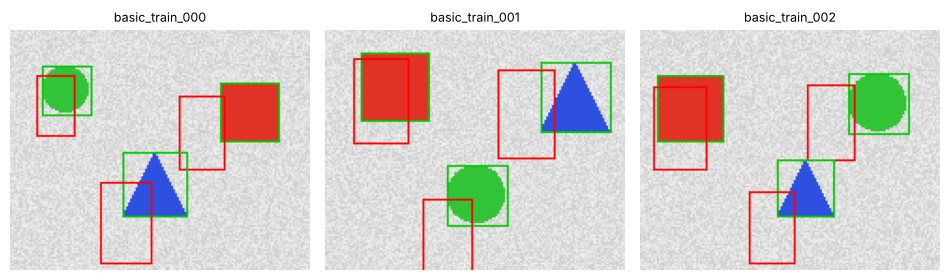

In [4]:
# ============================================================
# 3. 올바른 변환 vs W·H를 바꾼 변환
# ============================================================
panels = []; titles = []
for stem in labels.image.unique()[:3]:
    img = cv2.imread(str(DATA / "images/train" / f"{stem}.png"))
    for r in labels[labels.image == stem].itertuples():
        # 올바름 : x는 W, y는 H
        cv2.rectangle(img, (round(r.x1), round(r.y1)), (round(r.x2), round(r.y2)), (0, 200, 0), 1)
        # 잘못됨 : x에 H(128), y에 W(160)를 곱함
        bx1, by1 = (r.cx - r.w/2) * H, (r.cy - r.h/2) * W
        bx2, by2 = (r.cx + r.w/2) * H, (r.cy + r.h/2) * W
        cv2.rectangle(img, (round(bx1), round(by1)), (round(bx2), round(by2)), (0, 0, 255), 1)
    panels.append(img); titles.append(stem)
cv2.imwrite(str(OUT / "p03_label_check.png"), np.hstack(panels))
show(panels, titles)

## 4. 잘못된 변환의 IoU

바꿔 쓴 박스는 정답 박스와 얼마나 겹치는지 계산한다.

In [5]:
# ============================================================
# 4. 잘못된 변환의 IoU
# ============================================================
def iou(a, b):
    """xyxy 박스 두 개의 IoU (0~1)."""
    w = max(0, min(a[2], b[2]) - max(a[0], b[0])); h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    i = w * h
    return i / ((a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - i)

swap = []
for r in labels.itertuples():
    good = [r.x1, r.y1, r.x2, r.y2]
    bad = [(r.cx - r.w/2) * H, (r.cy - r.h/2) * W, (r.cx + r.w/2) * H, (r.cy + r.h/2) * W]
    swap.append(iou(good, bad))
labels["iou_if_swapped"] = swap
print("W·H를 바꿨을 때 정답과의 IoU: 평균", round(float(np.mean(swap)), 4), "최소", round(float(np.min(swap)), 4), "최대", round(float(np.max(swap)), 4))
labels[["image", "cls", "iou_if_swapped"]].round(4).head(6)

W·H를 바꿨을 때 정답과의 IoU: 평균 0.1812 최소 0.0 최대 0.4669


,image,cls,iou_if_swapped
0,basic_train_000,0,0.0309
1,basic_train_000,1,0.3764
2,basic_train_000,2,0.1321
3,basic_train_001,0,0.4669
4,basic_train_001,1,0.0943
5,basic_train_001,2,0.0857


## 정리 (README 설명 질문)

- **width와 height를 바꿔 정규화하면?** 160×128처럼 정사각형이 아닌 이미지에서는 박스 위치·크기가 가로로 0.8배, 세로로 1.25배 틀어진다. 위 실행에서 바뀐 박스와 정답의 IoU 평균·최소값이 그 손실을 보여 준다. 이 상태로 학습하면 모델은 틀린 위치를 배우고, 평가에서는 정답과 IoU가 낮아 FP·FN이 늘어난다.